# 호텔 예약 취소 예측 — DecisionTree (random_state=0)
기본 모델은 Accuracy, RandomizedSearchCV와 GridSearchCV는 F1-score로 평가합니다.

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

# 1. 데이터 읽기
df = pd.read_csv('hotel_preprocessed.csv')

# 2. 원핫인코딩: 식별자와 분할 정보는 학습에서 제외
df2 = df.drop(columns=['source_row_id', 'group_id', 'split'])
categorical_cols = df2.select_dtypes(include=['object', 'category']).columns.tolist()
df_onehot = pd.get_dummies(df2, columns=categorical_cols, dtype=int)

# 3. X, y 와 기존 train/test 구분
X = df_onehot.drop(columns=['is_canceled'])
y = df_onehot['is_canceled']
train_mask = df['split'].eq('train')
test_mask = df['split'].eq('test')
X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (95367, 578) Test: (23841, 578)


In [2]:
# 4. 기본 DecisionTree (Accuracy)
dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, pred_dt)
print(f'기본 DecisionTree Accuracy: {acc_dt:.4f}')

기본 DecisionTree Accuracy: 0.8214


In [3]:
# 5. RandomizedSearchCV (F1 최적화)
param_random = {
    'max_depth': [10, 12, 15, 16, 18, 20, 22, 25, 30],
    'min_samples_split': [5, 10, 15, 20, 30, 40],
    'min_samples_leaf': [2, 3, 5, 7, 10, 15],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}
random_search = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_distributions=param_random,
    n_iter=300, cv=5, scoring='f1', n_jobs=-1, random_state=0
)
random_search.fit(X_train, y_train)
random_pred = random_search.predict(X_test)
print('Random 최적 파라미터:', random_search.best_params_)
print(f'Random 교차검증 F1: {random_search.best_score_:.4f}')
print(f'Random 테스트 F1: {f1_score(y_test, random_pred):.4f}')

Random 최적 파라미터: {'min_samples_split': 30, 'min_samples_leaf': 2, 'max_depth': 10, 'criterion': 'entropy', 'class_weight': None}
Random 교차검증 F1: 0.4790
Random 테스트 F1: 0.7689


In [4]:
# 6. GridSearchCV (RandomizedSearchCV의 결과 주변 탐색)
param_grid = {
    'max_depth': [16, 18, 20, 22, 24],
    'min_samples_split': [12, 15, 18],
    'min_samples_leaf': [3, 5, 7, 10],
    'criterion': ['gini']
}
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),
    param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1
)
grid_search.fit(X_train, y_train)
grid_pred = grid_search.predict(X_test)
print('Grid 최적 파라미터:', grid_search.best_params_)
print(f'Grid 교차검증 F1: {grid_search.best_score_:.4f}')
print(f'Grid 테스트 F1: {f1_score(y_test, grid_pred):.4f}')

Grid 최적 파라미터: {'criterion': 'gini', 'max_depth': 24, 'min_samples_leaf': 7, 'min_samples_split': 18}
Grid 교차검증 F1: 0.4213
Grid 테스트 F1: 0.7744


In [5]:
print(f'기본 모델 Accuracy : {acc_dt:.4f}')
print(f'Random 모델 F1    : {f1_score(y_test, random_pred):.4f}')
print(f'Grid 모델 F1      : {f1_score(y_test, grid_pred):.4f}')

기본 모델 Accuracy : 0.8214
Random 모델 F1    : 0.7689
Grid 모델 F1      : 0.7744


### best 모델 저장

In [6]:
import joblib

if random_search.best_score_ >= grid_search.best_score_:
    best_model = random_search.best_estimator_
else:
    best_model = grid_search.best_estimator_

joblib.dump(best_model, 'hotel_best_model.pkl')

print("베스트 모델 저장 완료!")

베스트 모델 저장 완료!


### 기본 DecisionTree 결과

In [7]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.85      0.86      0.86     15002
           1       0.77      0.75      0.76      8839

    accuracy                           0.82     23841
   macro avg       0.81      0.81      0.81     23841
weighted avg       0.82      0.82      0.82     23841



### RandomizedSearchCV 결과

In [8]:
from sklearn.metrics import classification_report

random_pred = random_search.predict(X_test)

print("=== RandomizedSearchCV ===")
print(classification_report(y_test, random_pred))

=== RandomizedSearchCV ===
              precision    recall  f1-score   support

           0       0.85      0.90      0.87     15002
           1       0.81      0.73      0.77      8839

    accuracy                           0.84     23841
   macro avg       0.83      0.82      0.82     23841
weighted avg       0.84      0.84      0.84     23841



### GridSearchCV 결과

In [9]:
grid_pred = grid_search.predict(X_test)

print("=== GridSearchCV ===")
print(classification_report(y_test, grid_pred))

=== GridSearchCV ===
              precision    recall  f1-score   support

           0       0.86      0.89      0.87     15002
           1       0.80      0.75      0.77      8839

    accuracy                           0.84     23841
   macro avg       0.83      0.82      0.82     23841
weighted avg       0.84      0.84      0.84     23841



### 세 모델 결과

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

# 비교할 모델들을 딕셔너리로 정의
models = {
    "기본 DecisionTree": dt,
    "RandomizedSearchCV": random_search.best_estimator_,
    "GridSearchCV": grid_search.best_estimator_
}

# 반복문을 통해 각 모델의 결과(분류 보고서 + ROC-AUC) 일괄 출력
for name, model in models.items():
    print(f"\n===== {name} =====")

    # 예측값 및 예측 확률 계산
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] # 양성 클래스(1)에 대한 확률

    # Classification Report 출력
    print(classification_report(
        y_test,
        y_pred,
        digits=4
    ))
    
    # ROC-AUC 점수 출력
    roc_auc = roc_auc_score(y_test, y_proba)
    print(f"ROC-AUC: {roc_auc:.4f}")


===== 기본 DecisionTree =====
              precision    recall  f1-score   support

           0     0.8534    0.8648    0.8591     15002
           1     0.7652    0.7479    0.7565      8839

    accuracy                         0.8214     23841
   macro avg     0.8093    0.8063    0.8078     23841
weighted avg     0.8207    0.8214    0.8210     23841

ROC-AUC: 0.8079

===== RandomizedSearchCV =====
              precision    recall  f1-score   support

           0     0.8499    0.9006    0.8745     15002
           1     0.8123    0.7299    0.7689      8839

    accuracy                         0.8373     23841
   macro avg     0.8311    0.8153    0.8217     23841
weighted avg     0.8359    0.8373    0.8354     23841

ROC-AUC: 0.9159

===== GridSearchCV =====
              precision    recall  f1-score   support

           0     0.8585    0.8886    0.8733     15002
           1     0.7990    0.7513    0.7744      8839

    accuracy                         0.8377     23841
   macro 

### 과적합 비교

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd

# 비교할 모델 설정
models = {
    "기본 DecisionTree": dt,
    "RandomizedSearchCV": random_search.best_estimator_,
    "GridSearchCV": grid_search.best_estimator_
}

results = []

for name, model in models.items():

    # 학습 및 테스트 데이터 예측값 계산
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # 학습 및 테스트 데이터 예측 확률 계산 (ROC-AUC용)
    train_proba = model.predict_proba(X_train)[:, 1]
    test_proba = model.predict_proba(X_test)[:, 1]

    # 성능 지표 계산
    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)
    
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    
    train_auc = roc_auc_score(y_train, train_proba)
    test_auc = roc_auc_score(y_test, test_proba)

    # 결과 저장 리스트에 추가
    results.append({
        "모델": name,
        "학습 F1": round(train_f1, 4),
        "테스트 F1": round(test_f1, 4),
        "F1 차이": round(train_f1 - test_f1, 4),
        "학습 Accuracy": round(train_acc, 4),
        "테스트 Accuracy": round(test_acc, 4),
        "학습 ROC-AUC": round(train_auc, 4),
        "테스트 ROC-AUC": round(test_auc, 4)
    })

# DataFrame으로 변환
result_df = pd.DataFrame(results)

# CSV 파일로 저장 (엑셀에서 열 때 한글이 깨지지 않도록 utf-8-sig 사용)
csv_filename = 'model_performance_comparison.csv'
result_df.to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"모든 모델 성능 결과가 '{csv_filename}' 파일로 저장되었습니다!")

# 화면에 결과 표 출력
display(result_df)

모든 모델 성능 결과가 'model_performance_comparison.csv' 파일로 저장되었습니다!


,모델,학습 F1,테스트 F1,F1 차이,학습 Accuracy,테스트 Accuracy,학습 ROC-AUC,테스트 ROC-AUC
0,기본 DecisionTree,0.9929,0.7565,0.2364,0.9947,0.8214,0.9999,0.8079
1,RandomizedSearchCV,0.7818,0.7689,0.0129,0.8429,0.8373,0.9226,0.9159
2,GridSearchCV,0.8763,0.7744,0.1019,0.9099,0.8377,0.9756,0.8903


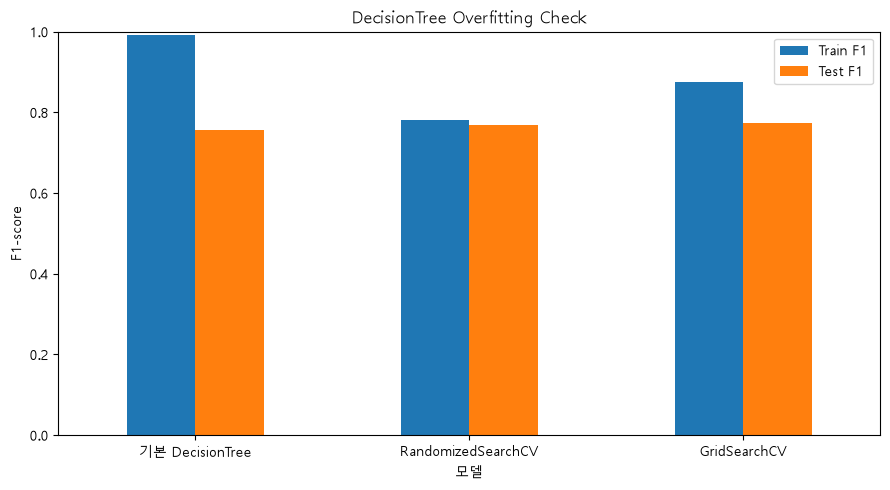

In [ ]:
# 시각화
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

result_df.set_index("모델")[["학습 F1", "테스트 F1"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("DecisionTree Overfitting Check")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(["Train F1", "Test F1"])
plt.tight_layout()
plt.show()


학습용 특성 중요도 CSV 저장 완료!
===== 학습용 특성 중요도 =====


,특성명,중요도
0,country_PRT,0.116347
1,agent_9,0.072464
2,lead_time,0.066993
3,total_of_special_requests,0.065247
4,market_segment_Online TA,0.059957
...,...,...
573,arrival_date_month_February,0.000000
574,customer_type_Contract,0.000000
575,customer_type_Group,0.000000
576,arrival_date_month_January,0.000000


평가용 특성 중요도 CSV 저장 완료!
===== 평가용 특성 중요도 =====


,특성명,중요도
0,country_PRT,0.112683
1,agent_9,0.070392
2,lead_time,0.063398
3,market_segment_Online TA,0.062523
4,total_of_special_requests,0.058855
...,...,...
573,agent_348,-0.000031
574,agent_14,-0.000034
575,arrival_date_week_number,-0.000061
576,country_DEU,-0.000079


학습용 특성 중요도 그래프 이미지 저장 완료!


<Figure size 1000x700 with 0 Axes>

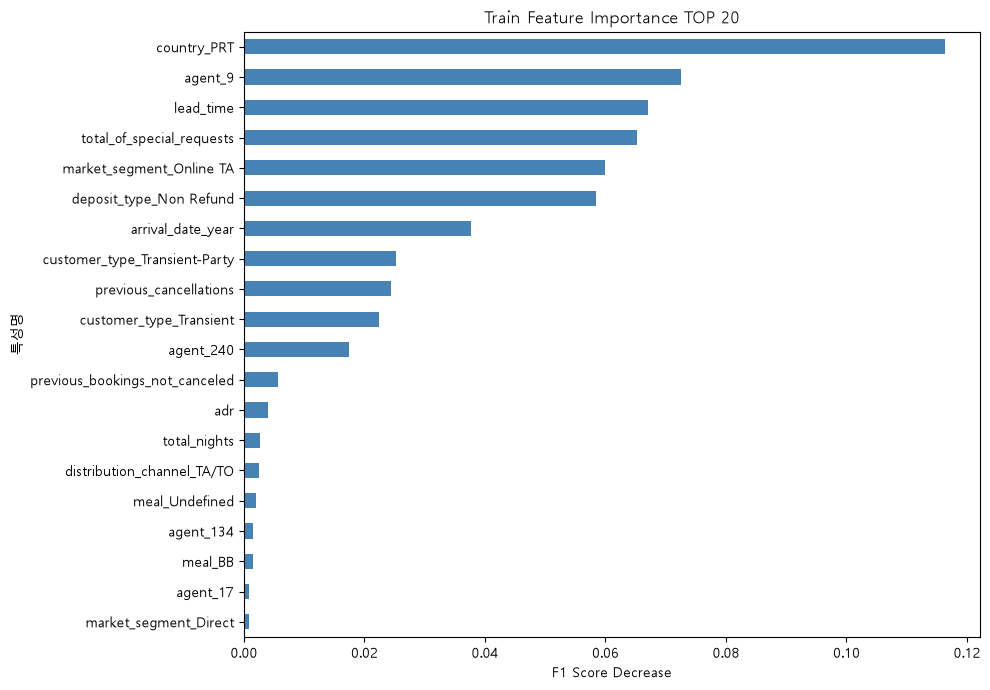

평가용 특성 중요도 그래프 이미지 저장 완료!


<Figure size 1000x700 with 0 Axes>

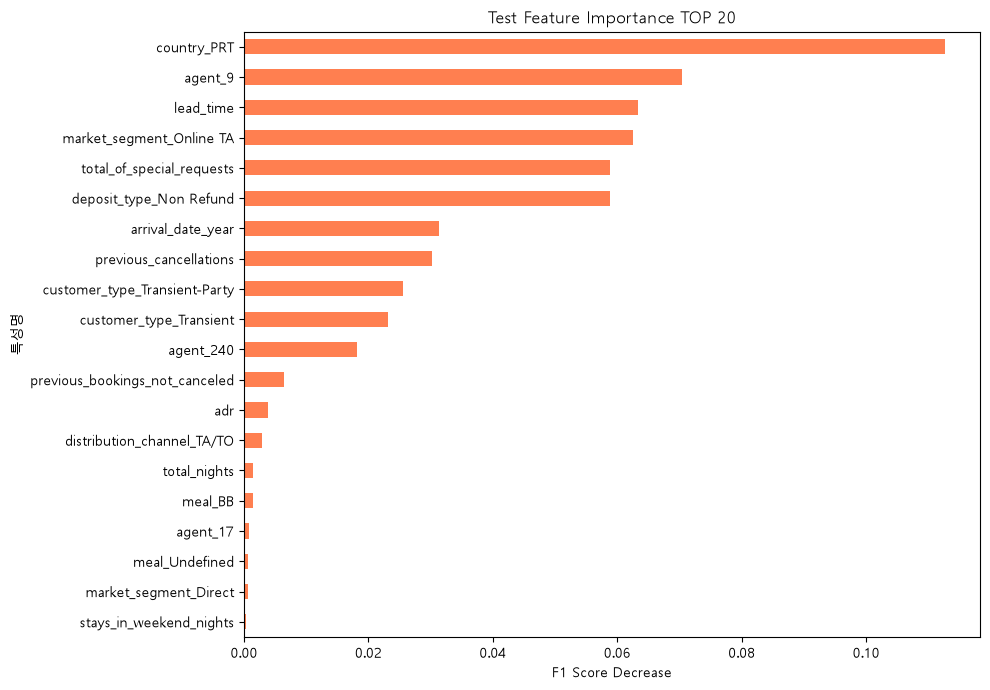

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from IPython.display import display

# 한글 폰트 및 마이너스 기호 설정 (이미 설정되어 있다면 생략 가능)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 기존 학습 완료 모델 사용 (재학습 없음)

# 학습용 특성 중요도 계산
train_imp = permutation_importance(
    best_model, X_train, y_train,
    scoring='f1', n_repeats=3,
    random_state=42, n_jobs=1
)

train_df = pd.DataFrame({
    '특성명': X_train.columns,
    '중요도': train_imp.importances_mean
}).sort_values('중요도', ascending=False).reset_index(drop=True)

# 학습용 특성 중요도 CSV 저장
train_df.to_csv('train_feature_importance.csv', index=False, encoding='utf-8-sig')
print("학습용 특성 중요도 CSV 저장 완료!")

print("===== 학습용 특성 중요도 =====")
display(train_df)


# 평가용 특성 중요도 계산
test_imp = permutation_importance(
    best_model, X_test, y_test,
    scoring='f1', n_repeats=3,
    random_state=42, n_jobs=1
)

test_df = pd.DataFrame({
    '특성명': X_test.columns,
    '중요도': test_imp.importances_mean
}).sort_values('중요도', ascending=False).reset_index(drop=True)

# 평가용 특성 중요도 CSV 저장
test_df.to_csv('test_feature_importance.csv', index=False, encoding='utf-8-sig')
print("평가용 특성 중요도 CSV 저장 완료!")

print("===== 평가용 특성 중요도 =====")
display(test_df)


# 학습용 중요도 시각화 및 이미지 저장
plt.figure(figsize=(10, 7))
train_df.head(20).sort_values('중요도').plot(
    x='특성명', y='중요도',
    kind='barh', figsize=(10, 7),
    color='steelblue', legend=False
)
plt.title('Train Feature Importance TOP 20')
plt.xlabel('F1 Score Decrease')
plt.tight_layout()

# 그래프를 PNG 이미지로 저장 (plt.show() 전에 실행해야 함)
plt.savefig('train_feature_importance.png', dpi=300)
print("학습용 특성 중요도 그래프 이미지 저장 완료!")
plt.show()


# 평가용 중요도 시각화 및 이미지 저장
plt.figure(figsize=(10, 7))
test_df.head(20).sort_values('중요도').plot(
    x='특성명', y='중요도',
    kind='barh', figsize=(10, 7),
    color='coral', legend=False
)
plt.title('Test Feature Importance TOP 20')
plt.xlabel('F1 Score Decrease')
plt.tight_layout()

# 그래프를 PNG 이미지로 저장 (plt.show() 전에 실행해야 함)
plt.savefig('test_feature_importance.png', dpi=300)
print("평가용 특성 중요도 그래프 이미지 저장 완료!")
plt.show()